# Résoudre de grands systèmes linéaires avec des méthodes itératives

On cherche $x$ tel que $Ax = b$ quand $A$ est grande (des milliers de lignes) et souvent creuse.
Au lieu d'inverser $A$ (beaucoup trop cher), on part d'un vecteur $x^{(0)}$ et on l'améliore
à chaque itération. Ce notebook compare quatre façons de faire :

- **Jacobi**, en version matrice pleine (dense) puis en version creuse (sparse, format CSR)
- **Gauss-Seidel**
- **SOR** (Successive Over-Relaxation), qui ajoute un paramètre de relaxation $\omega$

Toutes ces méthodes reposent sur le découpage $A = D - L - U$ ($D$ la diagonale, $-L$ la partie
strictement inférieure, $-U$ la partie strictement supérieure). Elles s'écrivent
$x^{(k+1)} = B\,x^{(k)} + c$ et convergent **si et seulement si le rayon spectral $\rho(B) < 1$**.
Plus $\rho(B)$ est proche de 0, plus ça va vite.

In [1]:
import os
import time

import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.sparse import csr_matrix, tril, triu
from scipy.sparse.linalg import spsolve_triangular

np.random.seed(0)
os.makedirs("figures", exist_ok=True)
EPS = 1e-5          # tolérance sur l'erreur ||x_k - x_exact||
MAX_ITER = 5000

## Les méthodes

**Jacobi** : chaque composante est recalculée à partir de l'itéré précédent uniquement,

$$x^{(k+1)} = D^{-1}\big(b - (A - D)\,x^{(k)}\big)$$

ce qui se vectorise très bien (un produit matrice-vecteur puis une division par la diagonale).

**Gauss-Seidel** : on utilise tout de suite les composantes déjà mises à jour, ce qui revient à
résoudre un système triangulaire inférieur à chaque itération :

$$(D - L)\,x^{(k+1)} = b + U x^{(k)}$$

**SOR** : on « exagère » le pas de Gauss-Seidel d'un facteur $\omega$ :

$$(D - \omega L)\,x^{(k+1)} = \big[(1-\omega)D + \omega U\big]x^{(k)} + \omega b$$

Avec $\omega = 1$ on retrouve Gauss-Seidel. Les quatre fonctions renvoient la solution, le nombre
d'itérations, l'historique de l'erreur et le temps de calcul. Le calcul s'arrête aussi si l'erreur
explose (méthode divergente), pour éviter un overflow.

In [2]:
def _boucle(etape, x0, x_exact, tol, max_iter):
    x, erreurs = x0.copy(), []
    debut = time.perf_counter()
    for k in range(1, max_iter + 1):
        x = etape(x)
        err = np.linalg.norm(x - x_exact)
        erreurs.append(err)
        if err < tol or not np.isfinite(err) or err > 1e12:
            break
    return x, k, erreurs, time.perf_counter() - debut


def jacobi_dense(A, b, x0, x_exact, tol=EPS, max_iter=MAX_ITER):
    D = np.diag(A)
    R = A - np.diag(D)                       # A sans sa diagonale
    return _boucle(lambda x: (b - R @ x) / D, x0, x_exact, tol, max_iter)


def jacobi_sparse(A, b, x0, x_exact, tol=EPS, max_iter=MAX_ITER):
    D = A.diagonal()
    R = (A - sp.diags(D)).tocsr()            # seules les valeurs non nulles sont stockées
    return _boucle(lambda x: (b - R @ x) / D, x0, x_exact, tol, max_iter)


def gauss_seidel_sparse(A, b, x0, x_exact, tol=EPS, max_iter=MAX_ITER):
    DL = tril(A, format="csr")               # D - L (diagonale comprise)
    U = triu(A, k=1, format="csr")           # partie strictement supérieure (= -U)
    return _boucle(lambda x: spsolve_triangular(DL, b - U @ x, lower=True), x0, x_exact, tol, max_iter)


def sor_sparse(A, b, x0, x_exact, w, tol=EPS, max_iter=MAX_ITER):
    D = sp.diags(A.diagonal(), format="csr")
    L = -tril(A, k=-1, format="csr")
    U = -triu(A, k=1, format="csr")
    M = (D - w * L).tocsr()                  # triangulaire inférieure
    N = ((1 - w) * D + w * U).tocsr()
    wb = w * b
    return _boucle(lambda x: spsolve_triangular(M, N @ x + wb, lower=True), x0, x_exact, tol, max_iter)


def rayon_spectral_jacobi(A):
    """rho(D^-1 (L+U)) calculé avec les valeurs propres (matrice dense, n raisonnable)."""
    A = A.toarray() if sp.issparse(A) else A
    D = np.diag(A)
    B = -(A - np.diag(D)) / D[:, None]
    return max(abs(np.linalg.eigvals(B)))

Quelques générateurs de matrices. `tridiag(n, a, c)` construit la matrice tridiagonale avec `a` sur
la diagonale et `c` juste au-dessus et en dessous, directement au format creux. Avec `a = 2`,
`c = -1` et le facteur $1/h^2$ ($h = 1/(n+1)$), c'est le laplacien 1D, la discrétisation de $-u''$.

In [3]:
def tridiag(n, a, c, avec_h=False):
    A = sp.diags([np.full(n - 1, c, dtype=float), np.full(n, a, dtype=float), np.full(n - 1, c, dtype=float)],
                 [-1, 0, 1], format="csr")
    if avec_h:
        A = A * (n + 1) ** 2               # 1 / h^2
    return A


def matrice_aleatoire(n, densite, diag):
    """Matrice avec environ `densite` % de cases non nulles, diagonale forte pour que Jacobi converge."""
    A = np.random.rand(n, n) * (np.random.rand(n, n) < densite)
    np.fill_diagonal(A, diag * n)
    return A


def matrice_fleche(n):
    """Première ligne, première colonne et diagonale remplies : 3n - 2 valeurs non nulles."""
    A = np.zeros((n, n))
    A[0, :] = 1.0
    A[:, 0] = 1.0
    np.fill_diagonal(A, 2.0 * n)
    return A

## 1. Jacobi sur trois familles de matrices

Une condition **suffisante** pour que Jacobi converge est la dominance diagonale stricte :
$|a_{ii}| > \sum_{j \ne i} |a_{ij}|$ sur chaque ligne. La condition **nécessaire et suffisante**,
c'est $\rho(B_J) < 1$. Les trois cas suivants montrent la différence entre les deux.

| Cas | Diagonale | Hors diagonale |
|---|---|---|
| 1 | $a_{ii} = 5(i+1)$ | $-1$ |
| 2 | $a_{ii} = 2n$ | $-1$ |
| 3 | $a_{ii} = 2 + 1{,}5\sin(i)$ | $n/2$ |

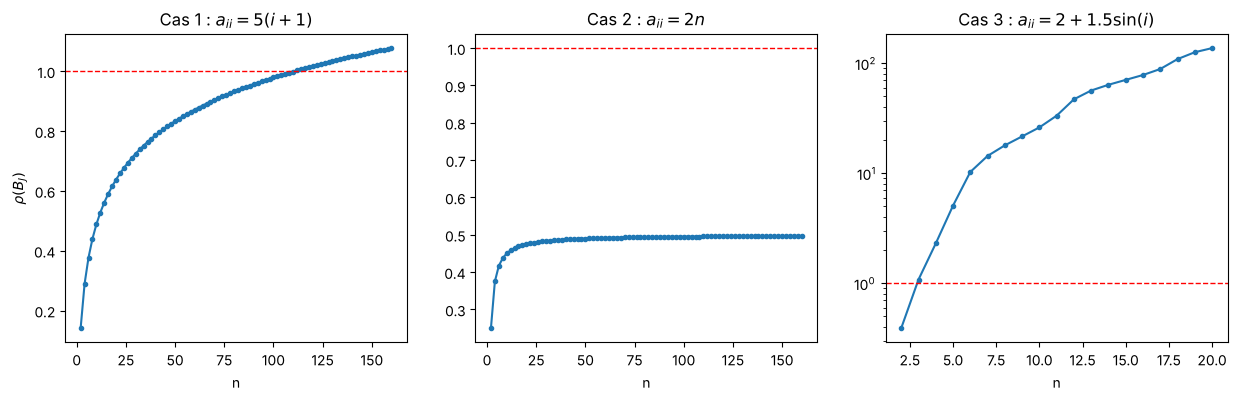

Cas 1, n = 109 : rho = 0.99722
Cas 1, n = 110 : rho = 0.99913
Cas 1, n = 111 : rho = 1.00102
Cas 1, n = 112 : rho = 1.00290
Cas 3, n = 2 : rho = 0.3915 | n = 3 : rho = 1.0811


In [4]:
def cas1(n):
    A = -np.ones((n, n)); np.fill_diagonal(A, 5 * (np.arange(n) + 1)); return A

def cas2(n):
    A = -np.ones((n, n)); np.fill_diagonal(A, 2 * n); return A

def cas3(n):
    A = np.full((n, n), n / 2); np.fill_diagonal(A, 2 + 1.5 * np.sin(np.arange(n))); return A


tailles = np.arange(2, 161, 2)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, cas, titre in zip(axes, [cas1, cas2, cas3], ["Cas 1 : $a_{ii}=5(i+1)$", "Cas 2 : $a_{ii}=2n$", "Cas 3 : $a_{ii}=2+1.5\\sin(i)$"]):
    tt = tailles if cas is not cas3 else np.arange(2, 21)
    ax.plot(tt, [rayon_spectral_jacobi(cas(n)) for n in tt], ".-")
    ax.axhline(1, color="red", ls="--", lw=1)
    ax.set_title(titre)
    ax.set_xlabel("n")
axes[0].set_ylabel(r"$\rho(B_J)$")
axes[2].set_yscale("log")
plt.show()

for n in (109, 110, 111, 112):
    print(f"Cas 1, n = {n} : rho = {rayon_spectral_jacobi(cas1(n)):.5f}")
print(f"Cas 3, n = 2 : rho = {rayon_spectral_jacobi(cas3(2)):.4f} | n = 3 : rho = {rayon_spectral_jacobi(cas3(3)):.4f}")

- **Cas 1.** La ligne $i$ est dominante seulement si $5(i+1) > n-1$, donc les premières lignes ne le
  sont plus quand $n$ grandit. Pourtant Jacobi converge encore tant que $\rho < 1$ : le rayon spectral
  passe au-dessus de 1 **entre $n = 110$ et $n = 111$**. La dominance diagonale n'est qu'une condition
  suffisante.
- **Cas 2.** Toujours dominante ($2n > n-1$). On a $\rho = \frac{n-1}{2n} \to 0{,}5$ : convergence
  rapide quel que soit $n$.
- **Cas 3.** La diagonale reste entre 0,5 et 3,5 alors que la somme hors diagonale vaut $(n-1)n/2$.
  Seul $n = 2$ converge ($\rho \approx 0{,}39$) ; dès $n = 3$ le rayon spectral dépasse 1 et explose.

On le voit aussi directement sur l'erreur (échelle log) :

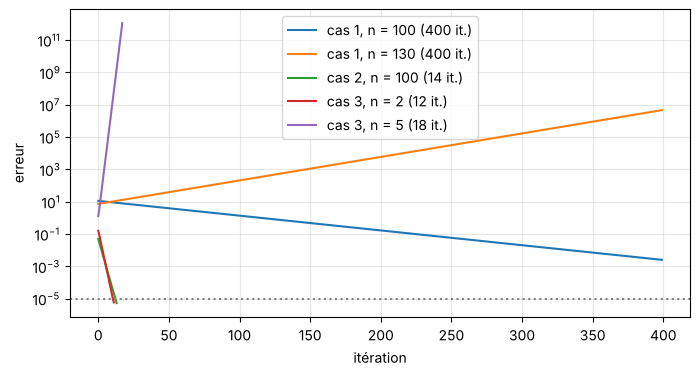

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
for A, nom in [(cas1(100), "cas 1, n = 100"), (cas1(130), "cas 1, n = 130"),
               (cas2(100), "cas 2, n = 100"), (cas3(2), "cas 3, n = 2"), (cas3(5), "cas 3, n = 5")]:
    b = np.ones(len(A))
    _, it, err, _ = jacobi_dense(A, b, np.zeros(len(A)), np.linalg.solve(A, b), max_iter=400)
    ax.semilogy(err, label=f"{nom} ({it} it.)")
ax.axhline(EPS, color="gray", ls=":")
ax.set_xlabel("itération"); ax.set_ylabel("erreur")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

Une droite qui descend = convergence (la pente vaut $\log \rho$), une droite qui monte = divergence.

## 2. Jacobi dense contre Jacobi sparse

Le format **COO** stocke une liste de triplets $(i, j, a_{ij})$ : pratique pour construire une matrice.
Le format **CSR** range les valeurs ligne par ligne avec, pour chaque ligne, l'indice de début dans
le tableau des colonnes : c'est le format fait pour les calculs (produit matrice-vecteur rapide).
Petit exemple :

In [6]:
petit = tridiag(5, 2, -1).tocoo()
print("COO  lignes  :", petit.row)
print("     colonnes:", petit.col)
print("     valeurs :", petit.data)
petit = petit.tocsr()
print("CSR  indptr  :", petit.indptr, " (la ligne i va de indptr[i] à indptr[i+1])")
print("     indices :", petit.indices)
print("     data    :", petit.data)

COO  lignes  : [0 0 1 1 1 2 2 2 3 3 3 4 4]
     colonnes: [0 1 0 1 2 1 2 3 2 3 4 3 4]
     valeurs : [ 2. -1. -1.  2. -1. -1.  2. -1. -1.  2. -1. -1.  2.]
CSR  indptr  : [ 0  2  5  8 11 13]  (la ligne i va de indptr[i] à indptr[i+1])
     indices : [0 1 0 1 2 1 2 3 2 3 4 3 4]
     data    : [ 2. -1. -1.  2. -1. -1.  2. -1. -1.  2. -1. -1.  2.]


Pour une matrice tridiagonale, le produit $Ax$ coûte $n^2$ multiplications en dense mais seulement
$\approx 3n$ en CSR. On mesure le temps de 200 itérations de Jacobi (même nombre d'itérations pour
les deux versions, pour ne comparer que le coût d'une itération).

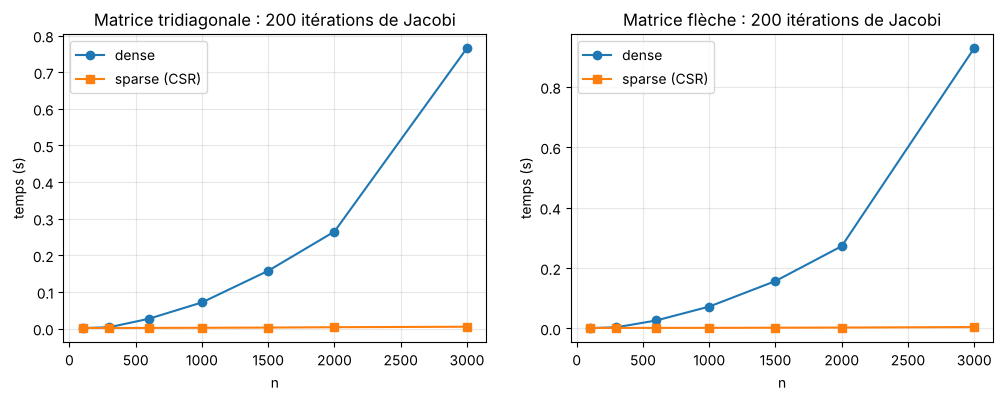

flèche n =  100 : dense 0.0011 s | sparse 0.0014 s | rapport    0.8
flèche n =  300 : dense 0.0038 s | sparse 0.0018 s | rapport    2.2
flèche n =  600 : dense 0.0264 s | sparse 0.0018 s | rapport   14.3
flèche n = 1000 : dense 0.0724 s | sparse 0.0020 s | rapport   36.6
flèche n = 1500 : dense 0.1570 s | sparse 0.0025 s | rapport   62.6
flèche n = 2000 : dense 0.2726 s | sparse 0.0030 s | rapport   91.6
flèche n = 3000 : dense 0.9286 s | sparse 0.0046 s | rapport  200.0


In [7]:
def temps_iterations(A_dense, A_sparse, n_iter=200):
    n = A_dense.shape[0]
    b, x0 = np.ones(n), np.zeros(n)
    # tol = 0 : le critère d'arrêt n'est jamais atteint, on fait exactement n_iter itérations
    t_d = jacobi_dense(A_dense, b, x0, x0, tol=0, max_iter=n_iter)[3]
    t_s = jacobi_sparse(A_sparse, b, x0, x0, tol=0, max_iter=n_iter)[3]
    return t_d, t_s


resultats = {"tridiagonale": [], "flèche": []}
tailles = [100, 300, 600, 1000, 1500, 2000, 3000]
for n in tailles:
    T = tridiag(n, 4, -1)
    resultats["tridiagonale"].append(temps_iterations(T.toarray(), T))
    F = matrice_fleche(n)
    resultats["flèche"].append(temps_iterations(F, csr_matrix(F)))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (nom, res) in zip(axes, resultats.items()):
    res = np.array(res)
    ax.plot(tailles, res[:, 0], "o-", label="dense")
    ax.plot(tailles, res[:, 1], "s-", label="sparse (CSR)")
    ax.set_title(f"Matrice {nom} : 200 itérations de Jacobi")
    ax.set_xlabel("n"); ax.set_ylabel("temps (s)")
    ax.legend(); ax.grid(alpha=0.3)
plt.show()
for n, (td, ts) in zip(tailles, resultats["flèche"]):
    print(f"flèche n = {n:4d} : dense {td:.4f} s | sparse {ts:.4f} s | rapport {td / ts:6.1f}")

Le temps du dense grandit comme $n^2$, celui du sparse reste presque plat (linéaire en $n$).
Pour $n = 1000$, la matrice flèche n'a que 2 998 valeurs utiles sur un million de cases : le dense
passe plus de 99,7 % de son temps à multiplier par zéro. Pour les très petites tailles le dense
reste compétitif, puis le sparse prend nettement l'avantage.

### Et si la matrice n'est pas si creuse ?

Le format CSR a un coût : pour chaque valeur il faut aussi lire son indice de colonne, alors qu'en
dense l'adresse d'une case se calcule directement. On fait varier la densité pour $n = 2000$.

In [8]:
n = 2000
print(f"{'densité':>8} | {'dense (s)':>9} | {'sparse (s)':>10} | gagnant")
for densite in (0.99, 0.95, 0.70, 0.40, 0.10, 0.01):
    A = matrice_aleatoire(n, densite, diag=200)
    td, ts = temps_iterations(A, csr_matrix(A), n_iter=50)
    print(f"{densite:8.2f} | {td:9.4f} | {ts:10.4f} | {'dense' if td < ts else 'sparse'}")

 densité | dense (s) | sparse (s) | gagnant
    0.99 |    0.0726 |     0.3659 | dense
    0.95 |    0.0788 |     0.3325 | dense
    0.70 |    0.0680 |     0.1488 | dense
    0.40 |    0.0713 |     0.0930 | dense
    0.10 |    0.1147 |     0.0241 | sparse
    0.01 |    0.0750 |     0.0024 | sparse


Sur une matrice presque pleine, le dense gagne : stocker et parcourir les indices ne sert à rien.
Ici le dense garde l'avantage jusque vers 40 % de remplissage ; en dessous, le sparse l'emporte, et
pour une densité de 1 % il n'y a pas photo. Les chiffres exacts dépendent de la machine, mais la
tendance reste la même.

## 3. Gauss-Seidel contre Jacobi

On prend la matrice tridiagonale $(-1, \alpha, -1)$ avec $n = 1000$ et on fait varier $\alpha$
(la dominance diagonale est stricte dès que $\alpha > 2$).

In [9]:
n = 1000
x0 = np.zeros(n)
print(f"{'alpha':>9} | {'rho_J':>7} | {'Jacobi':>16} | {'Gauss-Seidel':>16}")
for alpha in (1e6, 3, 2.1, 1.8):
    A = tridiag(n, alpha, -1)
    b = np.ones(n)
    x_ex = np.linalg.solve(A.toarray(), b)
    _, itJ, errJ, tJ = jacobi_sparse(A, b, x0, x_ex)
    _, itG, errG, tG = gauss_seidel_sparse(A, b, x0, x_ex)
    rho = 2 * np.cos(np.pi / (n + 1)) / alpha      # formule exacte pour cette matrice
    fmt = lambda it, err, t: "diverge" if err[-1] > 1 else f"{it:4d} it. {t:6.3f} s"
    print(f"{alpha:9.3g} | {rho:7.3f} | {fmt(itJ, errJ, tJ):>16} | {fmt(itG, errG, tG):>16}")

    alpha |   rho_J |           Jacobi |     Gauss-Seidel
    1e+06 |   0.000 |    1 it.  0.000 s |    1 it.  0.002 s
        3 |   0.667 |   37 it.  0.001 s |   22 it.  0.008 s
      2.1 |   0.952 |  354 it.  0.004 s |  181 it.  0.059 s
      1.8 |   1.111 |          diverge |          diverge


- $\alpha = 10^6$ : dominance écrasante, une ou deux itérations suffisent.
- $\alpha = 3$ : Gauss-Seidel fait nettement moins d'itérations que Jacobi.
- $\alpha = 2{,}1$ : dominance faible, $\rho_J$ proche de 1, la convergence est lente, et Gauss-Seidel
  fait **deux fois moins d'itérations** que Jacobi.
- $\alpha = 1{,}8$ : plus de dominance et $\rho_J > 1$, les deux méthodes divergent.

Le facteur 2 n'est pas un hasard : pour une matrice tridiagonale, le théorème de Young donne
$\rho(B_{GS}) = \rho(B_J)^2$. Une itération de Gauss-Seidel vaut deux itérations de Jacobi.

Mais en **temps de calcul**, Gauss-Seidel n'est pas forcément gagnant : Jacobi est un simple produit
matrice-vecteur, alors que Gauss-Seidel doit résoudre un système triangulaire, qui est séquentiel
(on a besoin de $x_1$ pour calculer $x_2$, etc.).

### Le cas difficile : le laplacien

Pour le laplacien ($\alpha = 2$, dominance juste à la limite) avec le facteur $1/h^2$, on a
$\rho_J = \cos\big(\frac{\pi}{n+1}\big)$, qui tend vers 1 quand $n$ grandit.

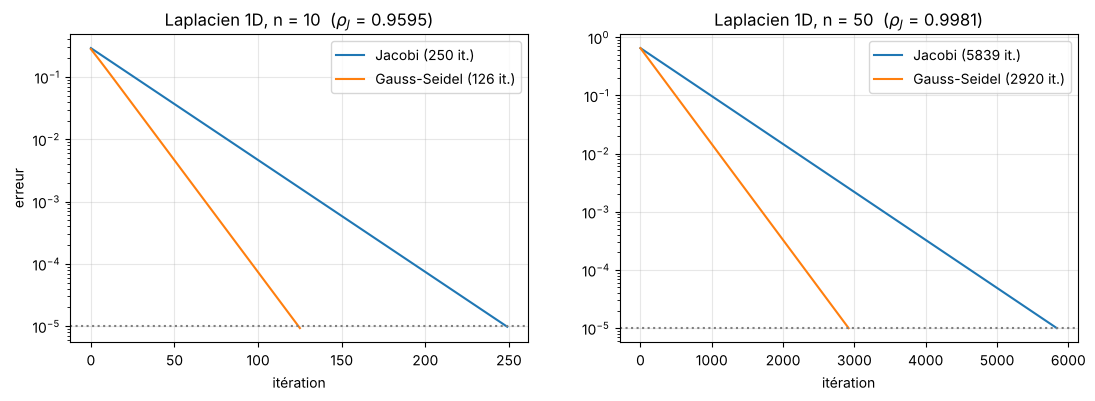

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, n in zip(axes, (10, 50)):
    A = tridiag(n, 2, -1, avec_h=True)
    b = np.ones(n)
    x_ex = np.linalg.solve(A.toarray(), b)
    for f, nom in [(jacobi_sparse, "Jacobi"), (gauss_seidel_sparse, "Gauss-Seidel")]:
        _, it, err, _ = f(A, b, np.zeros(n), x_ex, max_iter=20000)
        ax.semilogy(err, label=f"{nom} ({it} it.)")
    ax.axhline(EPS, color="gray", ls=":")
    ax.set_title(f"Laplacien 1D, n = {n}  ($\\rho_J$ = {np.cos(np.pi / (n + 1)):.4f})")
    ax.set_xlabel("itération"); ax.legend(); ax.grid(alpha=0.3)
axes[0].set_ylabel("erreur")
plt.show()

Gauss-Seidel garde son facteur 2, mais les deux méthodes deviennent très lentes quand $n$ augmente :
l'information ne se propage que d'une case par itération dans la barre, et le facteur $1/h^2$
rend le système mal conditionné. C'est exactement là que SOR devient intéressant.

## 4. La méthode SOR et le choix de $\omega$

On reste sur le laplacien avec $n = 50$ et on balaie $\omega$ entre 0 et 2. Pour avoir une erreur
comparable, on choisit $b = A\mathbf{1}$, la solution exacte est alors le vecteur de uns.

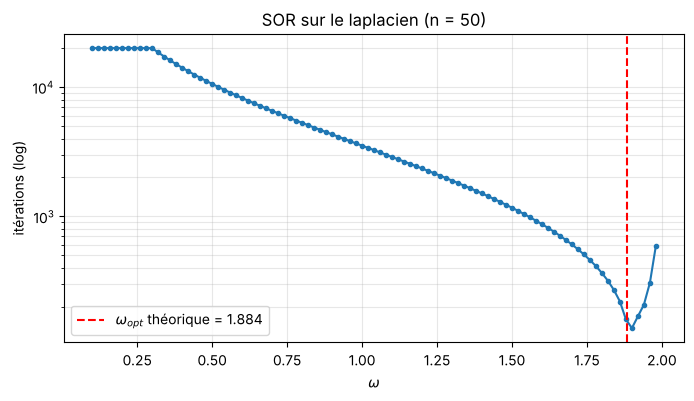

Meilleur omega testé : 1.9 (137 itérations), omega théorique : 1.884


In [11]:
n = 50
A = tridiag(n, 2, -1, avec_h=True)
x_ex = np.ones(n)
b = A @ x_ex
x0 = np.zeros(n)

omegas = np.round(np.arange(0.1, 2.0, 0.02), 2)
iterations = [sor_sparse(A, b, x0, x_ex, w, max_iter=20000)[1] for w in omegas]
rho_J = np.cos(np.pi / (n + 1))
w_theorique = 2 / (1 + np.sqrt(1 - rho_J ** 2))
w_meilleur = omegas[int(np.argmin(iterations))]

fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogy(omegas, iterations, ".-")
ax.axvline(w_theorique, color="red", ls="--", label=f"$\\omega_{{opt}}$ théorique = {w_theorique:.3f}")
ax.set_xlabel(r"$\omega$"); ax.set_ylabel("itérations (log)")
ax.set_title("SOR sur le laplacien (n = 50)")
ax.legend(); ax.grid(alpha=0.3, which="both")
plt.show()
print(f"Meilleur omega testé : {w_meilleur} ({min(iterations)} itérations), omega théorique : {w_theorique:.3f}")

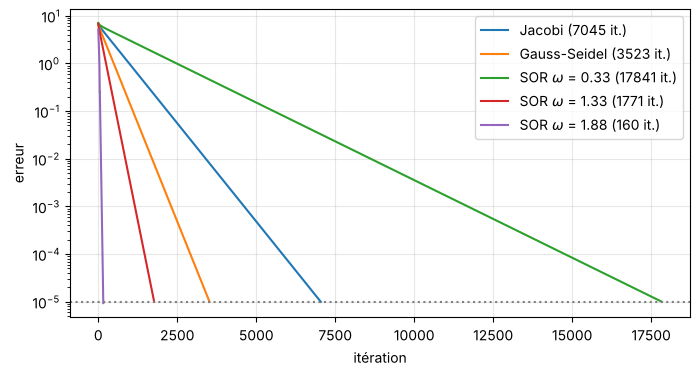

In [12]:
_, itJ, errJ, _ = jacobi_sparse(A, b, x0, x_ex, max_iter=20000)
_, itG, errG, _ = gauss_seidel_sparse(A, b, x0, x_ex, max_iter=20000)
fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogy(errJ, label=f"Jacobi ({itJ} it.)")
ax.semilogy(errG, label=f"Gauss-Seidel ({itG} it.)")
for w in (0.33, 1.33, round(w_theorique, 2)):
    _, it, err, _ = sor_sparse(A, b, x0, x_ex, w, max_iter=20000)
    ax.semilogy(err, label=f"SOR $\\omega$ = {w} ({it} it.)")
ax.axhline(EPS, color="gray", ls=":")
ax.set_xlabel("itération"); ax.set_ylabel("erreur")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

- $\omega = 0{,}33$ (sous-relaxation) : on freine Gauss-Seidel, c'est encore plus lent que Jacobi.
- $\omega = 1{,}33$ : on bat Gauss-Seidel, mais on est loin de l'optimum.
- $\omega \approx 1{,}89$ : le nombre d'itérations s'effondre. La valeur trouvée en balayant colle
  à la formule théorique $\omega_{opt} = \frac{2}{1 + \sqrt{1 - \rho_J^2}}$.

Pourquoi $\omega < 2$ ? Le théorème de Kahan donne $\rho(B_{SOR}) \geq |\omega - 1|$ : dès que
$\omega \geq 2$ (ou $\omega \leq 0$), le rayon spectral vaut au moins 1 et la méthode ne peut plus converger.

### Quand est-ce que SOR vaut le coup ?

Si la matrice est très dominante, $\rho_J$ est petit, donc $\omega_{opt} \approx 1$ : SOR ne fait
presque rien de plus que Gauss-Seidel. Pour le mesurer, on définit le coefficient de dominance
$\delta = |a_{ii}| / \sum_{j\neq i}|a_{ij}|$ et on compare Gauss-Seidel et SOR (avec son $\omega$
optimal) sur la matrice tridiagonale $(-1, 2\delta, -1)$, $n = 100$.

In [13]:
n = 100
x_ex = np.ones(n)
print(f"{'delta':>6} | {'omega_opt':>9} | {'GS':>6} | {'SOR':>5} | gain")
for delta in (1.0, 1.02, 1.05, 1.1, 1.5, 2.0, 3.0):
    A = tridiag(n, 2 * delta, -1)
    b = A @ x_ex
    rho = np.cos(np.pi / (n + 1)) / delta
    w = 2 / (1 + np.sqrt(1 - rho ** 2))
    itG = gauss_seidel_sparse(A, b, np.zeros(n), x_ex, max_iter=50000)[1]
    itS = sor_sparse(A, b, np.zeros(n), x_ex, w, max_iter=50000)[1]
    print(f"{delta:6.2f} | {w:9.3f} | {itG:6d} | {itS:5d} | x{itG / itS:.1f}")

 delta | omega_opt |     GS |   SOR | gain
  1.00 |     1.940 |  14175 |   285 | x49.7
  1.02 |     1.667 |    342 |    67 | x5.1
  1.05 |     1.531 |    143 |    44 | x3.2
  1.10 |     1.411 |     75 |    31 | x2.4
  1.50 |     1.146 |     20 |    15 | x1.3
  2.00 |     1.072 |     13 |    11 | x1.2
  3.00 |     1.029 |      9 |     8 | x1.1


Quand $\delta$ est grand (forte dominance), Gauss-Seidel suffit et SOR n'apporte presque rien.
Plus on se rapproche de $\delta = 1$ (le cas du laplacien), plus le gain devient énorme.
SOR est donc l'outil des problèmes « difficiles », à faible dominance diagonale.

## 5. Pour finir : les quatre méthodes côte à côte

Laplacien avec $n = 100$ (cas difficile) et matrice tridiagonale $(1, 15, 1)$ (cas facile).

Laplacien (2, -1) / h² : rho_J = 0.99952, omega_opt = 1.940
   Jacobi dense   :  23616 itérations, 0.167 s
   Jacobi sparse  :  23616 itérations, 0.170 s
   Gauss-Seidel   :  11809 itérations, 3.887 s
   SOR w=1.94     :    236 itérations, 0.067 s
Tridiagonale (15, 1) : rho_J = 0.13327, omega_opt = 1.004
   Jacobi dense   :      6 itérations, 0.000 s
   Jacobi sparse  :      6 itérations, 0.000 s
   Gauss-Seidel   :      4 itérations, 0.001 s
   SOR w=1.00     :      5 itérations, 0.001 s


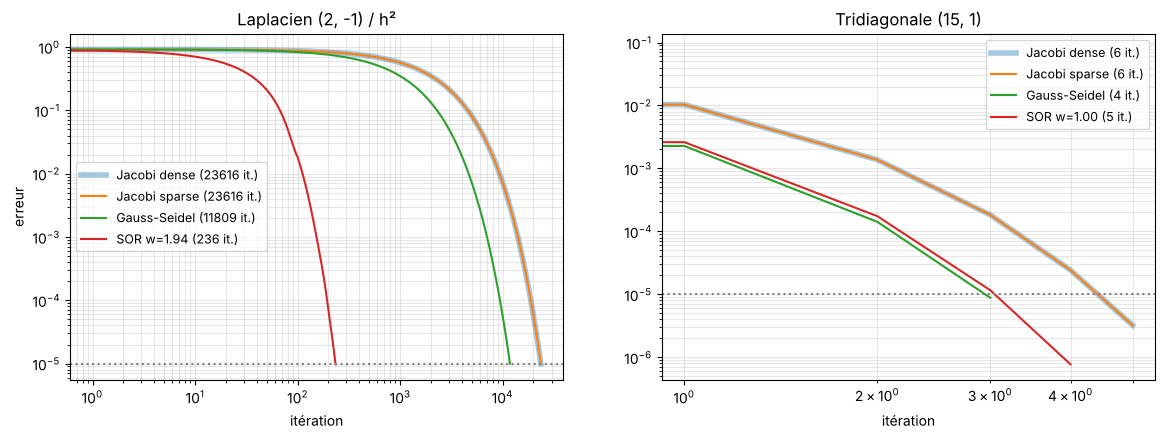

In [14]:
n = 100
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (A, titre) in zip(axes, [(tridiag(n, 2, -1, avec_h=True), "Laplacien (2, -1) / h²"),
                                 (tridiag(n, 15, 1), "Tridiagonale (15, 1)")]):
    b = np.ones(n)
    x_ex = np.linalg.solve(A.toarray(), b)
    rho = rayon_spectral_jacobi(A)
    w = 2 / (1 + np.sqrt(1 - rho ** 2))
    print(f"{titre} : rho_J = {rho:.5f}, omega_opt = {w:.3f}")
    for nom, res in [("Jacobi dense", jacobi_dense(A.toarray(), b, np.zeros(n), x_ex, max_iter=30000)),
                     ("Jacobi sparse", jacobi_sparse(A, b, np.zeros(n), x_ex, max_iter=30000)),
                     ("Gauss-Seidel", gauss_seidel_sparse(A, b, np.zeros(n), x_ex, max_iter=30000)),
                     (f"SOR w={w:.2f}", sor_sparse(A, b, np.zeros(n), x_ex, w, max_iter=30000))]:
        _, it, err, t = res
        print(f"   {nom:14s} : {it:6d} itérations, {t:.3f} s")
        ax.semilogy(err, label=f"{nom} ({it} it.)", lw=4 if nom == "Jacobi dense" else 1.5,
                    alpha=0.4 if nom == "Jacobi dense" else 1)
    ax.axhline(EPS, color="gray", ls=":")
    ax.set_title(titre); ax.set_xlabel("itération"); ax.set_xscale("log")
    ax.legend(fontsize=9); ax.grid(alpha=0.3, which="both")
axes[0].set_ylabel("erreur")
fig.savefig("figures/comparaison_methodes.png", dpi=150, bbox_inches="tight")
plt.show()

Jacobi dense et Jacobi sparse donnent exactement les mêmes itérés (les courbes sont superposées),
seul le temps change. Sur le cas facile tout le monde converge en quelques itérations. Sur le
laplacien, l'écart est énorme : il faut des dizaines de milliers d'itérations à Jacobi, environ
deux fois moins à Gauss-Seidel, et seulement quelques centaines à SOR avec le bon $\omega$.

## Bilan

- Le rayon spectral décide de tout, la dominance diagonale n'est qu'un test rapide.
- Le stockage creux est indispensable dès que la matrice est vraiment creuse, mais inutile si elle est pleine.
- Gauss-Seidel divise le nombre d'itérations par deux sur les matrices tridiagonales, sans forcément gagner en temps.
- SOR avec un bon $\omega$ change complètement la donne sur les problèmes mal conditionnés comme le laplacien.